In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("insurance.csv")

# Explore the dataset
print(df.head())

print(df.info())

print(df.describe())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   

In [19]:
print(df.shape)
print(df.columns)
print(df.info)
print( 'describe: ', df.describe(include = 'object'))
print('\n nombre de fumeur', (df['smoker'].value_counts()))

(1338, 7)
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')
<bound method DataFrame.info of       age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]>
describe:           sex smoker     re

C:\Users\YannUlysse\AppData\Local\Temp\ipykernel_24900\1561964108.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print( 'describe: ', df.describe(include = 'object'))


In [3]:
#rEGROUPER LES donnees selon une categories precise
df.groupby('smoker')['charges'].mean()
print(df.groupby('smoker')['charges'].mean())
print('\n', df.groupby('region')['charges'].mean())
print('\n',df.groupby('sex')['charges'].mean())

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64

 region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64

 sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64


In [4]:
#Étape suivante : Calculer les corrélations
#Puisque tu sais maintenant utiliser les bases, passons à l'étape 4. En Pandas, il existe une commande magique pour voir en un clin d'œil quelles colonnes influencent le plus les charges : la matrice de corrélation.

df.corr(numeric_only=True)


,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [5]:
#Prochaine étape : Croiser les indices
#Pour aller plus loin dans ton analyse exploratoire sans machine learning, on peut utiliser une autre fonction Pandas très populaire pour croiser deux colonnes (par exemple, voir le coût moyen selon l'âge et le fait d'être fumeur) ou visualiser tout cela.
print(df.groupby(['smoker', 'age'])['charges'].mean())

smoker  age
no      18      3215.162259
        19      3536.712898
        20      3673.112925
        21      3813.530413
        22      2551.017880
                   ...     
yes     60     48115.446238
        61     38578.794592
        62     37084.607312
        63     40331.784380
        64     39283.060036
Name: charges, Length: 94, dtype: float64


In [6]:
import pandas as pd

# 1. Créer des tranches d'âge pour structurer l'analyse (18-30 ans, 31-45 ans, 46-64 ans)
df['tranche_age'] = pd.cut(df['age'], bins=[18, 30, 45, 64], labels=['18-30 ans', '31-45 ans', '46-64 ans'])

# 2. Faire un tableau croisé (pivot table) pour voir la moyenne des charges selon l'âge ET le tabac
tableau_croise = df.groupby(['tranche_age', 'smoker'])['charges'].mean().unstack()

print(tableau_croise)

smoker                 no           yes
tranche_age                            
18-30 ans     4705.758286  27825.092529
31-45 ans     7246.170138  31707.164316
46-64 ans    12725.837177  37044.269389


In [7]:


# 2. Créer une colonne binaire pour le BMI (Obèse ou non)
df['statut_bmi'] = df['bmi'].apply(lambda x: 'Obèse (BMI >= 30)' if x >= 30 else 'Normal/Surpoids (BMI < 30)')

# 3. Créer un tableau croisé ultime avec pivot_table
tableau_ultime = df.pivot_table(
    values='charges', 
    index=['tranche_age', 'statut_bmi'], 
    columns='smoker', 
    aggfunc='mean'
)

print(tableau_ultime.unstack())

smoker                              no                    \
statut_bmi  Normal/Surpoids (BMI < 30) Obèse (BMI >= 30)   
tranche_age                                                
18-30 ans                  4598.295000       4834.229433   
31-45 ans                  7247.067658       7245.242898   
46-64 ans                 12528.914091      12860.916650   

smoker                             yes                    
statut_bmi  Normal/Surpoids (BMI < 30) Obèse (BMI >= 30)  
tranche_age                                               
18-30 ans                 17879.849258      37076.481618  
31-45 ans                 21739.843976      41447.954648  
46-64 ans                 25351.665826      46038.579822  


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Préparer les données : transformer le texte 'smoker' en chiffres (1 ou 0)
df['smoker_num'] = df['smoker'].apply(lambda x: 1 if x=='yes' else 0)

# 2. Choisir nos "indices" (variables) et ce qu'on veut prédire (la cible)
# On garde les trois grands facteurs qu'on a validés : l'âge, le BMI et le tabac
X = df[['age', 'bmi', 'smoker_num']]
y = df['charges']

# 3. Diviser les données (80% pour apprendre à l'ordinateur, 20% pour tester s'il a bon)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Créer et entraîner le modèle de Régression Linéaire
modele = LinearRegression()
modele.fit(X_train, y_train)

# 5. LA PRÉVISION : Testons sur un profil précis !
# Imaginons un nouveau client : 
# - Âge : 40 ans
# - BMI : 30 (limite obésité)
# - Fumeur : Oui (1)
nouveau_client = pd.DataFrame({
    'age': [40],
    'bmi': [30],
    'smoker_num': [1]
})

# L'ordinateur calcule la facture exacte prédite
prediction = modele.predict(nouveau_client)

print(f"Facture prédite pour ce profil : {prediction[0]:.2f} $")

Facture prédite pour ce profil : 32137.48 $


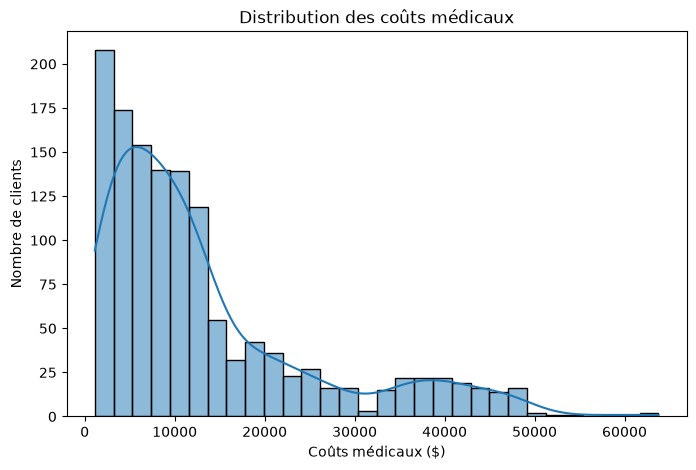

In [ ]:
#Graphique 1 : Distribution des coûts médicaux
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='charges', bins=30, kde=True)

plt.title('Distribution des coûts médicaux')
plt.xlabel('Coûts médicaux ($)')
plt.ylabel('Nombre de clients')

plt.show()

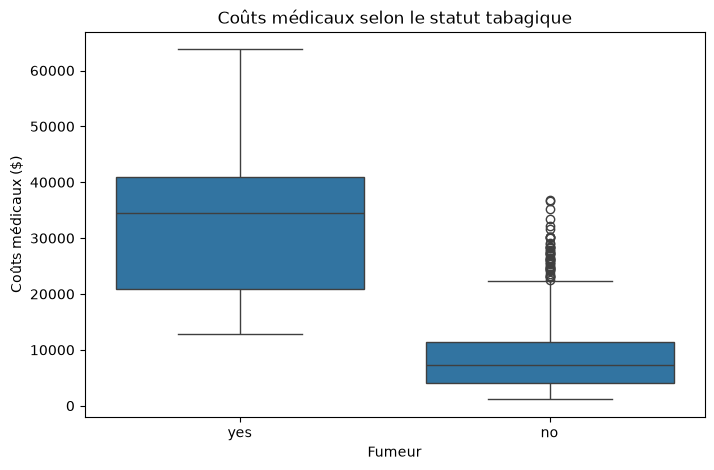

In [15]:
#Comparaison entre fumeurs et non-fumeurs
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='smoker', y='charges')

plt.title('Coûts médicaux selon le statut tabagique')
plt.xlabel('Fumeur')
plt.ylabel('Coûts médicaux ($)')

plt.show()

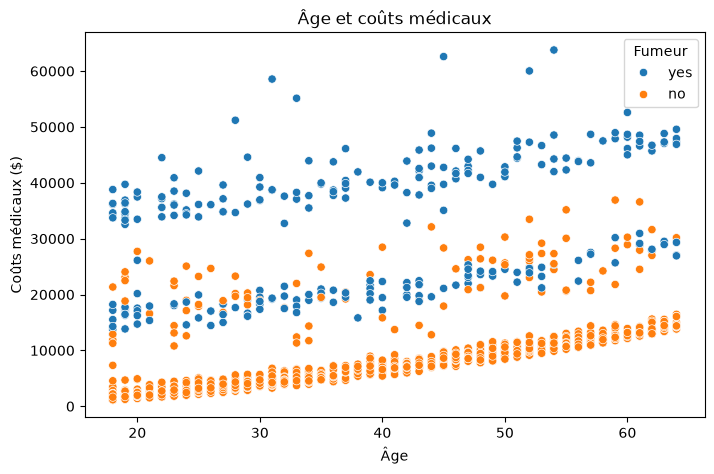

In [19]:
#Relation entre l'âge et les coûts médicaux
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='charges',
    hue='smoker'
)

plt.title('Âge et coûts médicaux')
plt.xlabel('Âge')
plt.ylabel('Coûts médicaux ($)')
plt.legend(title='Fumeur')

plt.show()


In [ ]:
#Le MAE mesure l'erreur absolue moyenne de tes prédictions.
#Le R² mesure dans quelle mesure ton modèle explique les variations des coûts médicaux dans les données de test.
from sklearn.metrics import mean_absolute_error, r2_score

# Faire des prédictions sur les données de test
y_pred = modele.predict(X_test)

# Calculer le MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculer le R²
r2 = r2_score(y_test, y_pred)

print(f"MAE : {mae:.2f} $")
print(f"R² : {r2:.4f}")

MAE : 4260.56 $
R² : 0.7777


In [ ]:
#Conclusion
# Conclusion – Insurance Cost Analysis & Prediction

#The objective of this project was to explore the relationship between customer characteristics and medical insurance charges, and to develop a simple predictive model using Python.
#The exploratory data analysis revealed several interesting patterns. First, the distribution of medical charges shows that costs are not evenly distributed across customers. Most observations are concentrated within certain lower and moderate cost ranges, while a smaller proportion of customers have considerably higher medical charges.
#The boxplot revealed a substantial difference between smokers and non-smokers. Smokers generally have significantly higher medical charges. The scatterplot also suggests a positive relationship between age and medical costs: as age increases, charges tend to increase as well.
#To explore these relationships further, I developed a multiple linear regression model using three predictors: age, BMI and smoking status.
#The model achieved an R² score of approximately 0.78, meaning that it explains about 77.8% of the variation in medical charges within the test dataset. Its Mean Absolute Error (MAE) was approximately $4,260.56, indicating the average absolute difference between predicted and actual charges.
#Overall, the analysis suggests that smoking status and age are important factors associated with medical insurance charges in this dataset. However, the model remains a simplified predictive exercise. It uses only three variables and does not capture every factor that may influence medical costs. These findings also describe associations rather than proving causation.
#This project provided practical experience in exploratory data analysis, data visualization, predictive modelling and model evaluation using Python.
